# **IIC2115 Programación como Herramienta para la Ingeniería**  
### **Capítulo 3: Análisis de datos geoespaciales y redes**
## Cápsula: Análisis de Red Vial con Datos Geoespaciales


**Profesora**: Camila Vera Villa

En esta cápsula recorreremos un ejemplo completo que integra OSMnx, NetworkX y los datos geoespaciales del curso. Trabajaremos con la red vial de una comuna de Santiago, calcularemos rutas y analizaremos métricas de centralidad.

**Contenidos:**
1. Descarga de red vial con OSMnx
2. Exploración de la estructura del grafo
3. Integración con datos geoespaciales del curso
4. Cálculo de rutas más cortas
5. Métricas de centralidad y su visualización

---
## 1. Instalación e importación de librerías

Prmero instalamos librerías necesarias

In [1]:
!pip install osmnx
!pip install geopandas
!pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 2.9 MB/s eta 0:00:00


In [2]:
import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import urllib.request
import os

#### Resolver rutas

In [3]:
# descargar datos solo si no existen
if not os.path.exists("datos_geoespaciales"):
    zip_url = "https://raw.githubusercontent.com/IIC2115/Syllabus/main/Material%20de%20clases/Cap%C3%ADtulo%203/Notebooks/datos_geoespaciales.zip"
    urllib.request.urlretrieve(zip_url, "datos_geoespaciales.zip")
    import zipfile
    with zipfile.ZipFile("datos_geoespaciales.zip", "r") as z:
        z.extractall(".")
    print("datos descargados y extraídos")
else:
    print("datos ya disponibles")

# rutas relativas
comunas = gpd.read_file("datos_geoespaciales/Comunas/comunas.shp")

datos descargados y extraídos



## 2. Descarga de la red vial

Usamos `ox.graph_from_place()` para descargar la red vial de una comuna desde OpenStreetMap.

El parámetro `network_type` permite elegir el tipo de red: `"drive"` (vehículos), `"walk"` (peatonal), `"bike"` (bicicleta) o `"all"`.

In [4]:
# descargar la red vial vehicular de macul
grafo = ox.graph_from_place("Macul, Santiago, Chile", network_type="drive")

print(f"nodos: {grafo.number_of_nodes()}")
print(f"aristas: {grafo.number_of_edges()}")
print(f"tipo de grafo: {type(grafo)}")

nodos: 2188
aristas: 5419
tipo de grafo: <class 'networkx.classes.multidigraph.MultiDiGraph'>


El resultado es un `MultiDiGraph` de NetworkX: un grafo **dirigido** (las calles tienen sentido) que puede tener **múltiples aristas** entre los mismos nodos (por ejemplo, pistas paralelas).


## 3. Exploración de nodos y aristas

Podemos convertir el grafo a GeoDataFrames para explorar sus atributos de forma tabular.

In [5]:
# convertir a geodataframes
nodos, aristas = ox.graph_to_gdfs(grafo)

print("=== nodos ===")
print(nodos.head(3))
print(f"\ncolumnas: {list(nodos.columns)}")

=== nodos ===
                  y          x  street_count highway  ref  \
osmid                                                       
14760647 -33.485706 -70.619074             4     NaN  NaN   
14760650 -33.474920 -70.622897             4     NaN  NaN   
16106390 -33.508246 -70.612374             4     NaN  NaN   

                             geometry  
osmid                                  
14760647  POINT (-70.61907 -33.48571)  
14760650   POINT (-70.6229 -33.47492)  
16106390  POINT (-70.61237 -33.50825)  

columnas: ['y', 'x', 'street_count', 'highway', 'ref', 'geometry']


In [6]:
print("=== aristas ===")
print(aristas[["name", "highway", "length", "geometry"]].head(5))

=== aristas ===
                                             name    highway      length  \
u        v          key                                                    
14760647 3634244419 0     Avenida Isabel Riquelme    primary   21.742045   
         6058741489 0     Avenida Vicuña Mackenna    primary  121.990650   
14760650 266098701  0    Avenida Rodrigo de Araya  secondary  282.743515   
16106390 5703399254 0     Avenida Vicuña Mackenna    primary  208.540904   
16967600 206410486  0    Avenida Rodrigo de Araya  secondary  271.772609   

                                                                  geometry  
u        v          key                                                     
14760647 3634244419 0    LINESTRING (-70.61907 -33.48571, -70.61929 -33...  
         6058741489 0    LINESTRING (-70.61907 -33.48571, -70.61916 -33...  
14760650 266098701  0    LINESTRING (-70.6229 -33.47492, -70.62282 -33....  
16106390 5703399254 0    LINESTRING (-70.61237 -33.50825, -70.6126

Observaciones clave:
- Los **nodos** tienen coordenadas (`x`, `y`) y un `osmid`.
- Las **aristas** tienen `name` (calle), `highway` (tipo de vía), `length` (largo en metros) y `geometry` (LineString).


## 4. Visualización básica de la red

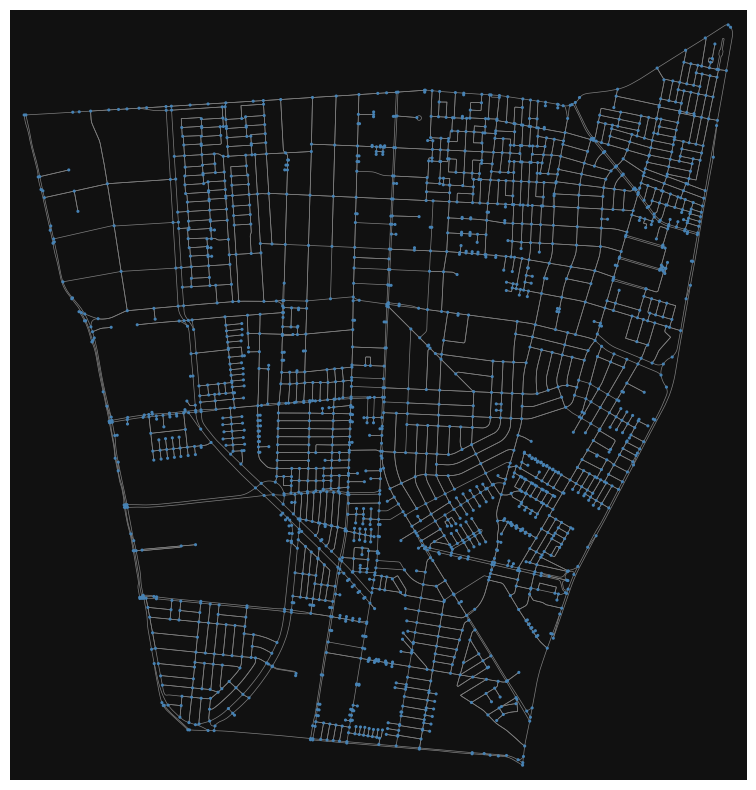

In [7]:
fig, ax = ox.plot_graph(grafo, node_size=5, node_color="steelblue",
                        edge_color="gray", edge_linewidth=0.5,
                        figsize=(10, 10))


## 5. Integración con datos geoespaciales del curso

Cargamos los datos geoespaciales del curso. Recuerden que estos datos están en la carpeta `datos_geoespaciales/` disponible en el sitio del curso.

In [8]:
# cargar datos geoespaciales del curso
comunas = gpd.read_file("datos_geoespaciales/Comunas/comunas.shp")
estaciones = gpd.read_file("datos_geoespaciales/Metro 2020/Estaciones_2020/Estaciones_2020.shp")
lineas = gpd.read_file("datos_geoespaciales/Metro 2020/Lineas_2020/Lineas_2020.shp")

print(f"comunas: {len(comunas)}")
print(f"estaciones de metro: {len(estaciones)}")
print(f"líneas de metro: {len(lineas)}")

comunas: 52
estaciones de metro: 127
líneas de metro: 137


In [9]:
comunas

,objectid,shape_leng,dis_elec,cir_sena,cod_comuna,codregion,st_area_sh,st_length_,Region,Comuna,Provincia,geometry
0,330,13987.326781,10,7,13129,13,1.424341e+07,16812.167615,Región Metropolitana de Santiago,San Joaquín,Santiago,"POLYGON ((-7861762.687 -3958307.095, -7861708...."
1,331,13311.641304,13,7,13130,13,1.389538e+07,15988.816037,Región Metropolitana de Santiago,San Miguel,Santiago,"POLYGON ((-7863229.775 -3964360.652, -7863319...."
2,332,11733.486710,13,7,13131,13,9.056280e+06,14061.528858,Región Metropolitana de Santiago,San Ramón,Santiago,"POLYGON ((-7863398.118 -3964354.273, -7863319...."
3,309,11488.695747,9,7,13108,13,1.068637e+07,14088.417488,Región Metropolitana de Santiago,Independencia,Santiago,"POLYGON ((-7865631.125 -3948404.075, -7865643...."
4,310,12797.595762,13,7,13109,13,1.454185e+07,15442.412755,Región Metropolitana de Santiago,La Cisterna,Santiago,"POLYGON ((-7865040.615 -3968217.521, -7865077...."
5,323,36618.971695,11,7,13122,13,7.709271e+07,43954.336968,Región Metropolitana de Santiago,Peñalolén,Santiago,"POLYGON ((-7852667.025 -3963533.211, -7852700...."
6,324,16072.408276,10,7,13123,13,2.073083e+07,19223.740933,Región Metropolitana de Santiago,Providencia,Santiago,"POLYGON ((-7857468.292 -3952687.257, -7857424...."
7,314,23724.899355,11,7,13113,13,3.361510e+07,28343.661508,Región Metropolitana de Santiago,La Reina,Santiago,"POLYGON ((-7852374.608 -3952376.018, -7852375...."
8,295,44852.016431,14,7,13403,13,1.056188e+08,54017.559247,Región Metropolitana de Santiago,Calera de Tango,Maipo,"POLYGON ((-7877355.549 -3971828.617, -7877326...."
9,288,172581.447530,8,7,13301,13,1.386968e+09,206660.187466,Región Metropolitana de Santiago,Colina,Chacabuco,"POLYGON ((-7879353.625 -3919889.834, -7879390...."


In [10]:
comunas.columns

Index(['objectid', 'shape_leng', 'dis_elec', 'cir_sena', 'cod_comuna',
       'codregion', 'st_area_sh', 'st_length_', 'Region', 'Comuna',
       'Provincia', 'geometry'],
      dtype='object')

In [11]:
# filtrar macul
macul = comunas[comunas["Comuna"] == "MACUL"].copy()

print(f"crs de la red: EPSG:4326 (osmnx siempre entrega en este crs)")
print(f"crs de comunas: {comunas.crs}")
print(f"crs de estaciones: {estaciones.crs}")

crs de la red: EPSG:4326 (osmnx siempre entrega en este crs)
crs de comunas: EPSG:3857
crs de estaciones: EPSG:32719


**Importante sobre CRS:** la red descargada con OSMnx usa EPSG:4326 (WGS 84, coordenadas lat/lon). Los datos `.shp` pueden tener otro CRS. Siempre hay que verificar y reproyectar si es necesario.

In [12]:
# reproyectar todo a epsg:4326 para que coincida con osmnx
if comunas.crs != "EPSG:4326":
    comunas = comunas.to_crs("EPSG:4326")
    macul = macul.to_crs("EPSG:4326")
if estaciones.crs != "EPSG:4326":
    estaciones = estaciones.to_crs("EPSG:4326")


## 6. Obtener el centroide de la comuna

Para calcular el centroide correctamente, proyectamos a un CRS métrico (UTM zona 19S para Santiago), calculamos el centroide, y luego reproyectamos a lat/lon.

In [13]:
# Asegurar que macul no esté vacío filtrando con insensibilidad a mayúsculas
macul = comunas[comunas["Comuna"].str.upper() == "MACUL"].copy()

# proyectar a utm zona 19s para calcular centroide en metros
macul_utm = macul.to_crs("EPSG:32719")
centroide_utm = macul_utm.geometry.centroid.iloc[0]

# reproyectar centroide a epsg:4326
centroide = gpd.GeoSeries([centroide_utm], crs="EPSG:32719").to_crs("EPSG:4326").iloc[0]

print(f"centroide de macul: ({centroide.y:.4f}, {centroide.x:.4f})")

centroide de macul: (-33.4894, -70.6000)



## 7. Ruta más corta pasando por el centroide

Calcularemos la ruta desde el extremo nororiente de Macul al surponiente, pasando por el centroide.

In [14]:
# definir puntos extremos (usando el bounding box de la comuna)
bounds = macul.total_bounds  # [minx, miny, maxx, maxy]

punto_ne = (bounds[3], bounds[2])  # lat=maxy, lon=maxx
punto_sw = (bounds[1], bounds[0])  # lat=miny, lon=minx

# encontrar nodos más cercanos
nodo_ne = ox.nearest_nodes(grafo, X=punto_ne[1], Y=punto_ne[0])
nodo_sw = ox.nearest_nodes(grafo, X=punto_sw[1], Y=punto_sw[0])
nodo_centro = ox.nearest_nodes(grafo, X=centroide.x, Y=centroide.y)

print(f"nodo nororiente: {nodo_ne}")
print(f"nodo surponiente: {nodo_sw}")
print(f"nodo centroide: {nodo_centro}")

nodo nororiente: 463014288
nodo surponiente: 457763495
nodo centroide: 515257889


In [15]:
# ruta en dos tramos: NE -> centroide -> SW
ruta_1 = nx.shortest_path(grafo, nodo_ne, nodo_centro, weight="length")
ruta_2 = nx.shortest_path(grafo, nodo_centro, nodo_sw, weight="length")
ruta_completa = ruta_1 + ruta_2[1:]  # evitar duplicar el nodo centroide

# largos
largo_1 = nx.shortest_path_length(grafo, nodo_ne, nodo_centro, weight="length")
largo_2 = nx.shortest_path_length(grafo, nodo_centro, nodo_sw, weight="length")
largo_total = largo_1 + largo_2

print(f"tramo NE -> centroide: {largo_1:.0f} m")
print(f"tramo centroide -> SW: {largo_2:.0f} m")
print(f"largo total: {largo_total:.0f} m")

tramo NE -> centroide: 4086 m
tramo centroide -> SW: 3083 m
largo total: 7168 m


In [16]:
# comparar con la ruta directa NE -> SW
ruta_directa = nx.shortest_path(grafo, nodo_ne, nodo_sw, weight="length")
largo_directo = nx.shortest_path_length(grafo, nodo_ne, nodo_sw, weight="length")

print(f"largo ruta directa: {largo_directo:.0f} m")
print(f"largo ruta por centroide: {largo_total:.0f} m")
print(f"diferencia: {largo_total - largo_directo:.0f} m ({(largo_total/largo_directo - 1)*100:.1f}% más larga)")

largo ruta directa: 6690 m
largo ruta por centroide: 7168 m
diferencia: 478 m (7.1% más larga)



## 8. Visualización de rutas

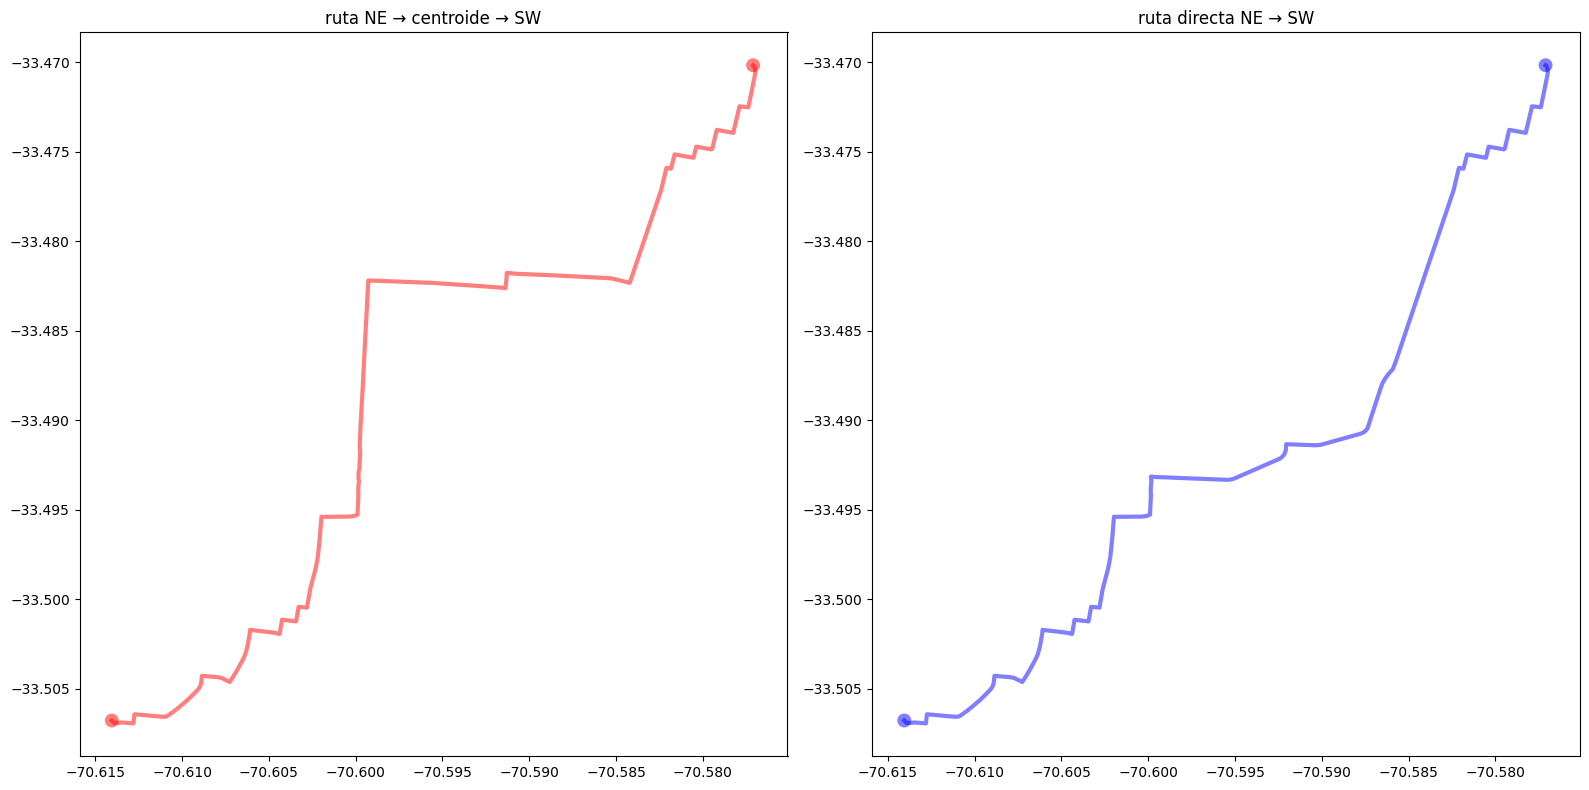

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# ruta por centroide
ox.plot_graph_route(grafo, ruta_completa, route_linewidth=3,
                    route_color="red", node_size=0,
                    edge_color="lightgray", edge_linewidth=0.5,
                    ax=axes[0], show=False, close=False)
axes[0].set_title("ruta NE → centroide → SW", fontsize=12)

# ruta directa
ox.plot_graph_route(grafo, ruta_directa, route_linewidth=3,
                    route_color="blue", node_size=0,
                    edge_color="lightgray", edge_linewidth=0.5,
                    ax=axes[1], show=False, close=False)
axes[1].set_title("ruta directa NE → SW", fontsize=12)

plt.tight_layout()
plt.show()


## 9. Integración con datos de accidentes

Cargamos los datos de accidentes (en formato GeoJSON) y los combinamos con la red.

In [18]:
# cargar datos de accidentes (puntos críticos)
puntos_criticos = gpd.read_file("datos_geoespaciales/Accidentes/Puntos_criticos_2019.geojson")
atropellos = gpd.read_file("datos_geoespaciales/Accidentes/Atropellos_2020.geojson")

print(f"puntos críticos: {len(puntos_criticos)}")
print(f"atropellos: {len(atropellos)}")
print(f"columnas puntos críticos: {list(puntos_criticos.columns)}")

puntos críticos: 802
atropellos: 981
columnas puntos críticos: ['FID', 'Ano', 'Codregion', 'Region', 'Comuna', 'Zona', 'Calle1', 'Calle2', 'Numero', 'lat', 'lng', 'Claseaccid', 'Cód_Comun', 'Tipo__CONA', 'Cód_Zona', 'Zona_1', 'Cód_Ubica', 'Ubicación', 'Cód_Calle', 'Intersecci', 'Pistas_de_', 'Pistas_de1', 'Cód_Calza', 'Calzada', 'Cód__Tipo', 'Tipo_Calza', 'Fallecidos', 'Graves', 'Menos_Grav', 'Leves', 'Accidentes', 'geometry']


In [19]:
# filtrar accidentes dentro de macul usando spatial join
if puntos_criticos.crs != macul.crs:
    puntos_criticos = puntos_criticos.to_crs(macul.crs)

accidentes_macul = gpd.sjoin(puntos_criticos, macul, predicate="within")
print(f"puntos críticos en macul: {len(accidentes_macul)}")

puntos críticos en macul: 16



## 10. Métricas de centralidad

Las métricas de centralidad nos permiten identificar los nodos más importantes de la red:

- **Centralidad de intermediación** (*betweenness*): cuántos caminos más cortos pasan por un nodo.
- **Centralidad de cercanía** (*closeness*): qué tan cerca está un nodo de todos los demás.

In [20]:
# calcular centralidad de intermediación (puede tomar unos segundos)
print("calculando centralidad de intermediación...")
centralidad_betweenness = nx.betweenness_centrality(grafo, weight="length")

# agregar al grafo
nx.set_node_attributes(grafo, centralidad_betweenness, "betweenness")

# actualizar geodataframe
nodos, aristas = ox.graph_to_gdfs(grafo)
print(f"betweenness - media: {nodos['betweenness'].mean():.6f}")
print(f"betweenness - max: {nodos['betweenness'].max():.6f}")

calculando centralidad de intermediación...
betweenness - media: 0.015661
betweenness - max: 0.156044



## 11. Visualización integradora: centralidad + accidentes

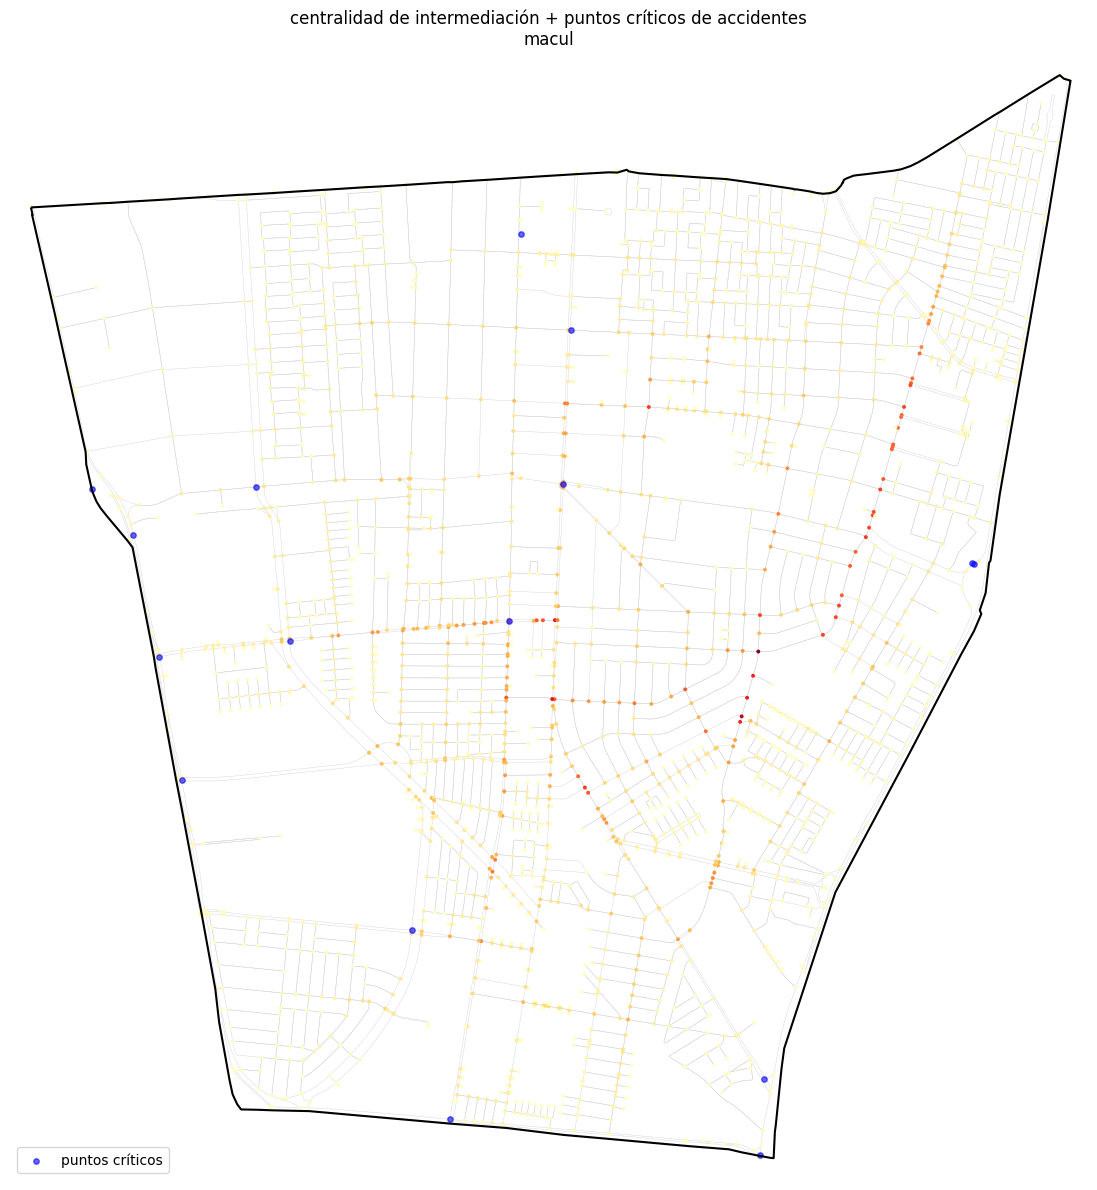

In [21]:
fig, ax = plt.subplots(figsize=(12, 12))

# capa 1: comuna
macul.boundary.plot(ax=ax, color="black", linewidth=1.5)

# capa 2: red coloreada por centralidad
node_bc = [centralidad_betweenness.get(n, 0) for n in grafo.nodes()]

# Normalizar valores para mapear con colormap manualmente
normalizer = plt.Normalize(vmin=min(node_bc), vmax=max(node_bc))
cmap = plt.cm.YlOrRd
node_colors = [cmap(normalizer(val)) for val in node_bc]

ox.plot_graph(grafo, node_size=8, node_color=node_colors,
              edge_color="lightgray", edge_linewidth=0.3,
              ax=ax, show=False, close=False)

# capa 3: accidentes
if len(accidentes_macul) > 0:
    accidentes_macul.plot(ax=ax, color="blue", markersize=15,
                          alpha=0.6, label="puntos críticos")

ax.legend(loc="lower left")
ax.set_title("centralidad de intermediación + puntos críticos de accidentes\nmacul",
             fontsize=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

---
## Resumen

En esta cápsula vimos cómo:

- **Descargar** redes viales con `ox.graph_from_place()` y explorar su estructura.
- **Integrar** datos geoespaciales del curso (comunas, estaciones de metro, accidentes) con la red.
- **Calcular rutas** más cortas con `nx.shortest_path()`, incluyendo pasos intermedios.
- **Analizar** la estructura de la red con métricas de centralidad.
- **Visualizar** rutas, centralidades y datos geoespaciales en mapas integradores.

Estas herramientas serán la base para los ejercicios formativos de esta semana.